# Model 2: K-Nearest Neighbors

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as ssplt
import seaborn as sns
from sklearn.cluster import KMeans

df = pd.read_csv("data/final_df.csv")
df.head()

,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label,final_group
0,blues.00000.wav,661794,0.350088,0.088757,0.130228,0.002827,1784.165850,129774.064525,2002.449060,85882.761315,...,-1.690215,36.524071,-0.408979,41.597103,-2.303523,55.062923,1.221291,46.936035,blues,Acoustic
1,blues.00001.wav,661794,0.340914,0.094980,0.095948,0.002373,1530.176679,375850.073649,2039.036516,213843.755497,...,-0.731125,60.314529,0.295073,48.120598,-0.283518,51.106190,0.531217,45.786282,blues,Acoustic
2,blues.00002.wav,661794,0.363637,0.085275,0.175570,0.002746,1552.811865,156467.643368,1747.702312,76254.192257,...,-7.729093,47.639427,-1.816407,52.382141,-3.439720,46.639660,-2.231258,30.573025,blues,Acoustic
3,blues.00003.wav,661794,0.404785,0.093999,0.141093,0.006346,1070.106615,184355.942417,1596.412872,166441.494769,...,-3.319597,50.206673,0.636965,37.319130,-0.619121,37.259739,-3.407448,31.949339,blues,Acoustic
4,blues.00004.wav,661794,0.308526,0.087841,0.091529,0.002303,1835.004266,343399.939274,1748.172116,88445.209036,...,-5.454034,75.269707,-0.916874,53.613918,-4.404827,62.910812,-11.703234,55.195160,blues,Acoustic


#### Because KNN suffers from curse of dimensionality we drop variables that will lead less to interpretability, and strictly focus on music related variables. 
- We also remove variables that don't add new information (variables that are colinear or lead to multicollinearty)

In [3]:
df = df.drop(['label', 'filename', 'length','mfcc1_mean', 'mfcc1_var', 'mfcc2_mean', 'mfcc2_var', 'mfcc3_mean',
       'mfcc3_var', 'mfcc4_mean', 'mfcc4_var', 'mfcc5_mean', 'mfcc5_var',
       'mfcc6_mean', 'mfcc6_var', 'mfcc7_mean', 'mfcc7_var', 'mfcc8_mean',
       'mfcc8_var', 'mfcc9_mean', 'mfcc9_var', 'mfcc10_mean', 'mfcc10_var',
       'mfcc11_mean', 'mfcc11_var', 'mfcc12_mean', 'mfcc12_var', 'mfcc13_mean',
       'mfcc13_var', 'mfcc14_mean', 'mfcc14_var', 'mfcc15_mean', 'mfcc15_var',
       'mfcc16_mean', 'mfcc16_var', 'mfcc17_mean', 'mfcc17_var', 'mfcc18_mean',
       'mfcc18_var', 'mfcc19_mean', 'mfcc19_var', 'mfcc20_mean', 'mfcc20_var'], axis=1)


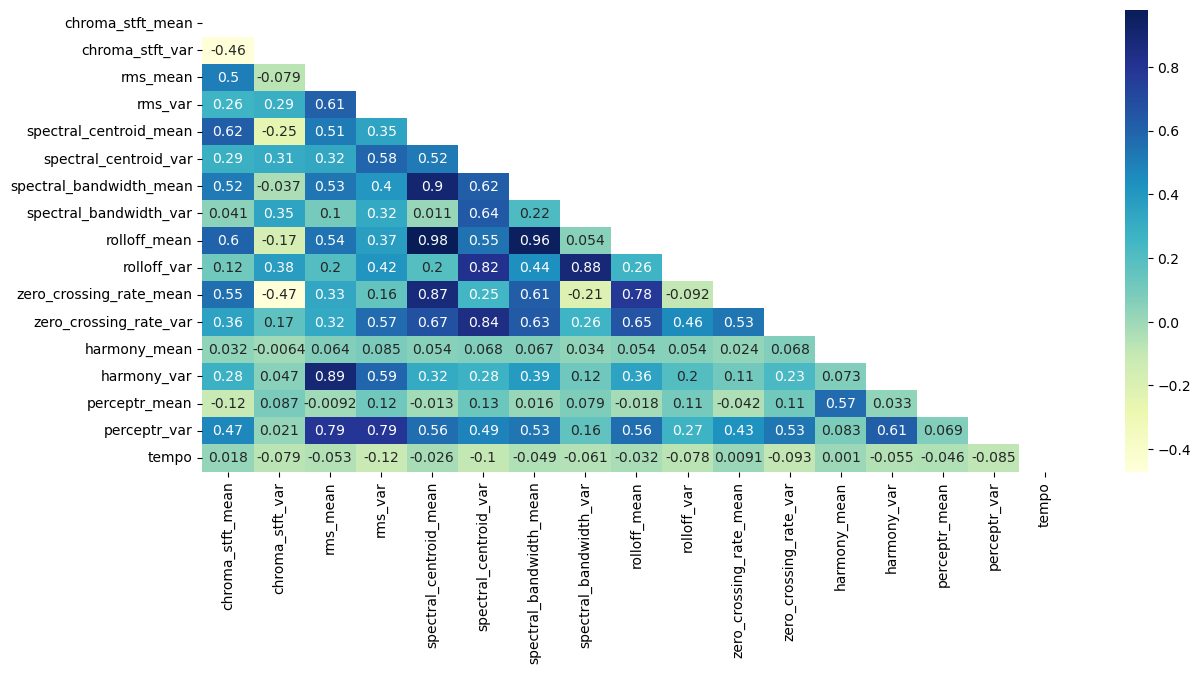

In [3]:
plt.figure(figsize=(14, 6)) 
corr_matrix = df.corr(numeric_only=True)
mask = np.triu(np.ones_like(df.corr(numeric_only=True)))
sns.heatmap(corr_matrix, cmap="YlGnBu", annot=True, mask=mask)
plt.show()

### Scaling
- Any distance based methods (K-means, KNN etc..) need features to be normalized otehrise it's drastically be affected by the units it uses. 

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
# Normalize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df.drop('final_group', axis=1)) #scale everything except target variable (it's a class)
y = df['final_group'] 
# Split into train and test
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42, stratify=y
)

In [6]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import classification_report

# Train a KNN classifier
knn = KNeighborsClassifier(n_neighbors=6)
knn.fit(X_train, y_train)

# Predict and evaluate
y_pred = knn.predict(X_test)
print(f"Test Accuracy (k=6): {accuracy_score(y_test, y_pred):.2f}")

# Evaluate with F1 scores and classification report
accuracy = accuracy_score(y_test, y_pred)
f1_weighted = f1_score(y_test, y_pred, average='weighted')
f1_macro = f1_score(y_test, y_pred, average='macro')

print("Accuracy:", accuracy)
print("Weighted F1:", f1_weighted)
print("Macro F1:", f1_macro)
print(classification_report(y_test, y_pred))

Test Accuracy (k=6): 0.73
Accuracy: 0.7266666666666667
Weighted F1: 0.728182788208009
Macro F1: 0.7335000014697366
              precision    recall  f1-score   support

    Acoustic       0.85      0.74      0.79        90
    Electric       0.70      0.76      0.73        90
    Rhythmic       0.67      0.69      0.68       120

    accuracy                           0.73       300
   macro avg       0.74      0.73      0.73       300
weighted avg       0.73      0.73      0.73       300



### Choosing optimal K
- The top cell is a baseline ran agaist k = 6. I had tried several differnet values manually replacing the parameter and seeing whether accuracy improved. However the best way to do this is to choose a range of k to test and then creating an elbow plot and observing what the best value is that gives us teh maxium accuracy in classification.
- Mental model on train, test, load model, fit and predict.
* `knn = KNeighborsClassifier(n_neighbors=k)`, This just creates the empty box and sets its settings (hyperparameters). Here you're saying "make a KNN that will consult k neighbors." No data has touched it yet — it knows nothing.
* `knn.fit(X_train, y_train)`, This is learning. You hand it the training features (X_train) and their correct answers (y_train) together, so it can learn the mapping from features → label. For most models fit does heavy computation.
* `y_pred = knn.predict(X_test)`, This is answering. You give it only the features it has never seen (X_test) — notice you do not give it y_test here. The model outputs its guessed labels, which you store in y_pred. So now you have two parallel lists: what the model guessed (y_pred) and the true answers (y_test), which you kept hidden.
* `accuracy_rate = accuracy_score(y_test, y_pred)`, This is grading. You compare the truth (y_test) against the guesses (y_pred). accuracy_score just counts what fraction matched. That's your metric.
So the whole rhythm is:

- Create → fit(train features + train answers) → predict(test features only) → score(true answers vs predictions).

- The key insight that ties it together: y_test is the answer key you hide during prediction and only reveal at grading time. That's the entire point of splitting — you test on data the model never learned from, so the accuracy reflects real generalization rather than memorization.

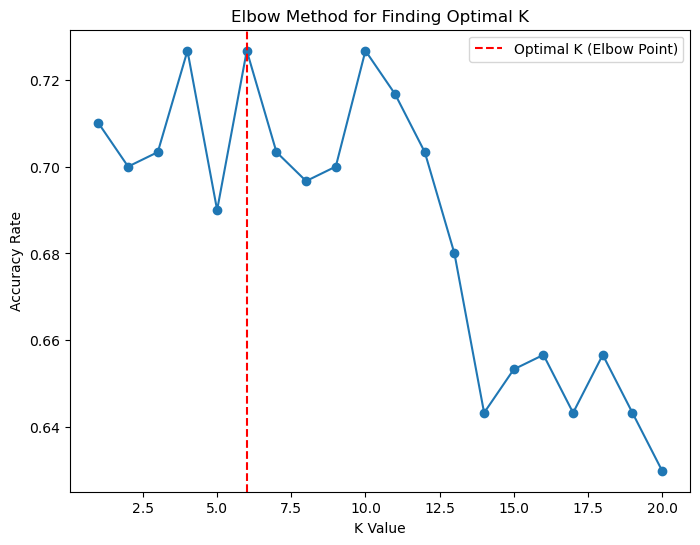

In [9]:
# VALIDATION CURVE
k_values = range(1, 21)
accuracy_rates =[]

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    accuracy_rate = accuracy_score(y_test, y_pred)
    accuracy_rates.append(accuracy_rate)

plt.figure(figsize=(8, 6))
plt.plot(k_values, accuracy_rates, marker='o')
plt.xlabel('K Value')
plt.ylabel('Accuracy Rate')
plt.title('Elbow Method for Finding Optimal K')
plt.axvline(x=6, linestyle='--', color='red', label="Optimal K (Elbow Point)")
plt.legend()
plt.show()

In [11]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
# Normalize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df.drop('final_group', axis=1)) #scale everything except target variable (it's a class)
y = df['final_group'] 
# Split into train and test
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42, stratify=y
)

# Tune K with 5-fold cross-validation — all inside the TRAINING data
k_values = range(1, 21)
cv_scores = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())   # average across the 5 folds

best_k = k_values[np.argmax(cv_scores)]
print(f"Best K (chosen by CV): {best_k}")

# Final honest score on the untouched test set
final_knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train, y_train)
print(f"Honest test accuracy: {accuracy_score(y_test, final_knn.predict(X_test)):.3f}")

Best K (chosen by CV): 3
Honest test accuracy: 0.703


In [6]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
# Normalize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df.drop('final_group', axis=1)) #scale everything except target variable (it's a class)
y = df['final_group'] 
# Split into train and test
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42, stratify=y
)
k_values = range(1, 21)
cv_scores = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())   # average across the 5 folds

best_k = k_values[np.argmax(cv_scores)]
print(f"Best K (chosen by CV): {best_k}")

# Final honest score on the untouched test set
final_knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train, y_train)
print(f"Honest test accuracy: {accuracy_score(y_test, final_knn.predict(X_test)):.3f}")

Best K (chosen by CV): 3
Honest test accuracy: 0.703


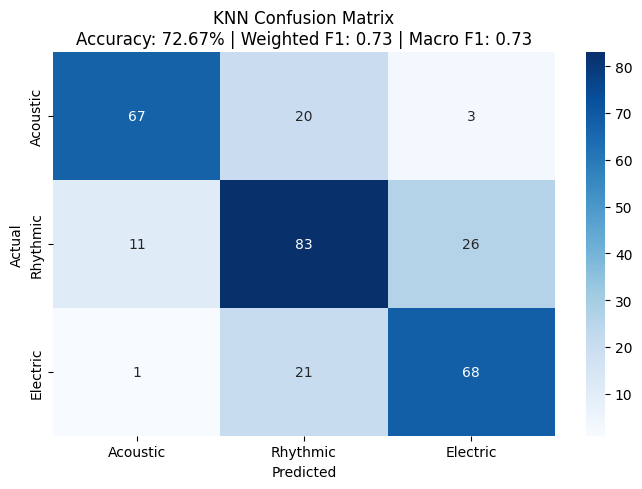

In [95]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

labels = ['Acoustic', 'Rhythmic', 'Electric']

cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)
plt.title(f'KNN Confusion Matrix\nAccuracy: {accuracy:.2%} | Weighted F1: {f1_weighted:.2f} | Macro F1: {f1_macro:.2f}')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

### Plotting the 2D and 3D Plots

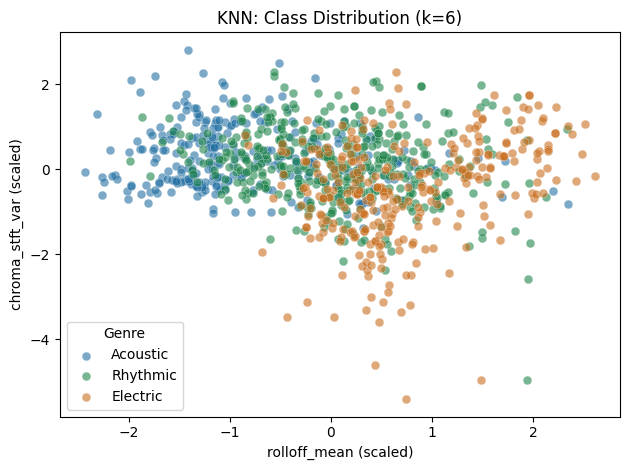

In [107]:
import matplotlib.pyplot as plt

feature_cols = [col for col in df.columns if col != 'final_group']
rolloff_idx = feature_cols.index('rolloff_mean')
centroid_idx = feature_cols.index('chroma_stft_var')

colors = {'Acoustic': '#2471a3', 'Rhythmic': '#1e8449', 'Electric': '#ca6f1e'}

for group, color in colors.items():
    mask = df['final_group'] == group
    plt.scatter(X_scaled[mask, rolloff_idx], 
                X_scaled[mask, centroid_idx],
                label=group, color=color, alpha=0.6, edgecolors='white', linewidths=0.3, s=40)

plt.xlabel('rolloff_mean (scaled)')
plt.ylabel('chroma_stft_var (scaled)')
plt.title('KNN: Class Distribution (k=6)')
plt.legend(title='Genre')
plt.tight_layout()
plt.show()

The 2D scatter plot of rolloff_mean vs. chroma_stft_var can be misleading. Classes that look overlapping may actually be separable once a third dimension is added, We do so in the bplot below (where we have added tempo as the z-axis).

In [ ]:
import plotly.express as px
import pandas as pd

rolloff_idx = feature_cols.index('rolloff_mean') #indexing/keeping track of original df to scaled df
chroma_idx = feature_cols.index('chroma_stft_var')
tempo_idx = feature_cols.index('tempo')

plot_df = pd.DataFrame({
    'rolloff_mean': X_scaled[:, rolloff_idx],
    'chroma_stft_var': X_scaled[:, chroma_idx],
    'tempo': X_scaled[:, tempo_idx],
    'final_group': df['final_group'].values
})

fig = px.scatter_3d(plot_df,
                    x='rolloff_mean',
                    y='chroma_stft_var',
                    z='tempo',
                    color='final_group',
                    opacity=0.7,
                    title='KNN: Class Distribution 3D (k=6)',
                    color_discrete_map={
                        'Acoustic': '#2471a3',
                        'Rhythmic': '#1e8449',
                        'Electric': '#ca6f1e'
                    },
                    labels={'final_group': 'Genre'})

fig.update_traces(marker=dict(size=6))
fig.update_layout(width=1000, height=800)
fig.show()